# 005. Nonradiative Transition Rates Using the Non-Adiabatic Coupling Vector

### VV0 center in 4H-SiC (*kk* configuration) simulated at the PBE level on a 5x5x2 cell with 398 atoms

The notebook is organized into two parts:

   1. Compute the electron-phonon coupling matrix element using the NAC vector obtained from TDDFT calculations.
   2. Compute the nonradiative rate.

In [1]:
%matplotlib widget

import os, sys
path = os.getcwd()
os.chdir(path)
sys.path.append('/home/svillani/Programs/pypl/pypl/')
import hr_nonrad_solver

import numpy as np
from scipy import constants
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'
deep_violet = '#9D80B8'
vibrant_purple = '#D391C2'
soft_coral = '#F3B1BA'
ocean_blue = '#81BFD6'
goldenrod_yellow = '#EBD68F'
emerald_green = '#02A650'

eV = constants.eV
amu = constants.physical_constants['atomic mass constant'][0]
hbar = constants.hbar
ry2eV = 13.6057039763
bohr2ang = 0.529177249

## 1. Compute the electron-phonon coupling matrix element using the NAC vectors obtained from TDDFT calculations.

In the spin-conserved TDDFT calculation, the ${}^3\!A_2$ state is the ground state, and the ${}^3\!E$ states are states 2 and 1. At the optimized geometry of the ${}^3\!A_2$ state, the ${}^3\!E$ states are doubly degenerate. At the optimized geometry of the ${}^3\!E$ state, the degeneracy is lifted. We will compute the electron-phonon coupling matrix elements between the ground state and both state 1 and state 2.

In [2]:
from hr_nonrad_solver import hr_nonrad_solver
from utils import *

# phonons are computed at the pbe level of theory
state_3A2_phonon_file = 'PBE/3A2_ph_mesh.hdf5'
# =========================================================================================
# PBE results
nac_3E_state1_3A2_file_pbe = 'PBE/3E/west.wbse.save/wbse.json'
nac_3E_state2_3A2_file_pbe = 'PBE/3E/west.wbse.save/wbse_1.json'
state_3E_pwscf_file_pbe = 'PBE/3E/pwscf.xml'
# Rydberg to eV
energy_3E_state1_pbe = 0.07319671319198932 * ry2eV  # at 3E relax geo
energy_3A2_pbe = 0.0
# =========================================================================================
# DDH results
nac_3E_state1_3A2_file_ddh = 'DDH/3E/west.wbse.save/wbse.json'
state_3E_pwscf_file_ddh = 'DDH/3E/pwscf.xml'
# Rydberg to eV
energy_3E_state1_ddh = 0.091847781854781471 * ry2eV  # at 3E relax geo
energy_3A2_ddh = 0.0

### Adiabatic transition energies (meV)
## experimental value 
adiabatic_energy_3E_3A2 = 1096
adiabatic_energy_3E_3A2_pbe = 971
adiabatic_energy_3E_3A2_ddh = 1351

In [3]:
def parse_forces_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    forces = np.array(data['output']['forces']['forces_corrected']).reshape(-1, 3)
    # Ry/bohr to eV/Angstrom
    forces *= (ry2eV / bohr2ang)
    return forces

def parse_nac_from_wbse_json(filename, nac_type):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec'][nac_type]).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

We can parse the NAC vector from the WEST output file

PBE results first

In [4]:
nac_vec_3E_state1_3A2_pbe = parse_nac_from_wbse_json(nac_3E_state1_3A2_file_pbe,'genac_corrected')
print(nac_vec_3E_state1_3A2_pbe.shape)
print(nac_vec_3E_state1_3A2_pbe[-5:])
print()

nac_vec_3E_state2_3A2_pbe = parse_nac_from_wbse_json(nac_3E_state2_3A2_file_pbe,'genac_corrected')
print(nac_vec_3E_state2_3A2_pbe.shape)
print(nac_vec_3E_state2_3A2_pbe[-5:])
print()

(398, 3)
[[ 2.53049802e-03  4.38025428e-03  6.20502404e-05]
 [ 1.42857349e-03 -3.84589896e-04 -2.86199986e-03]
 [-4.02304785e-03  1.04400805e-02  9.38290016e-03]
 [ 5.54402779e-05 -1.38667322e-03  1.87053634e-04]
 [ 1.26073333e-02  1.41398028e-02 -7.42278526e-03]]

(398, 3)
[[ 0.00162316 -0.00087076 -0.00203046]
 [-0.00052769  0.00086598  0.0025989 ]
 [-0.00437486 -0.00177719 -0.00865666]
 [-0.00023768 -0.0014672   0.00496828]
 [-0.03310595 -0.01336341 -0.02534786]]



DDH results 

In [5]:
nac_vec_3E_state1_3A2_ddh = parse_nac_from_wbse_json(nac_3E_state1_3A2_file_ddh,'genac_corrected')
print(nac_vec_3E_state1_3A2_ddh.shape)
print(nac_vec_3E_state1_3A2_ddh[-5:])
print(nac_vec_3E_state1_3A2_ddh.sum(axis=0))

(398, 3)
[[-0.04998935  0.02715732 -0.06395521]
 [ 0.00609468 -0.00836994  0.00737945]
 [-0.01108326 -0.15444907 -0.2213197 ]
 [ 0.00421356 -0.00951865 -0.00731855]
 [ 0.1394116  -0.06798578  0.22154873]]
[-2.22044605e-16 -6.66133815e-16 -1.11022302e-16]


Similar to the calculation of vibrationally resolved optical lineshapes, we parse the phonon frequencies and modes, atomic symbols, and cell parameters from the phonopy h5 file and the pwscf qexml file.

In [6]:
# Unit of freqs is THz
state_3A2_phonon_freqs, state_3A2_phonon_modes = parse_phonopy_h5(state_3A2_phonon_file)

mass_list = {'C': 12.0107, 'Si': 28.085}

Note that we use the dyn mat computed at the 3A2 GS

The total force acting on the final state (${}^3\!A_2$) is extracted from the DFT calculation in the 3E excited state

In [7]:
atomic_symbols_pbe, dft_forces_pbe = parse_forces_qexml(state_3E_pwscf_file_pbe)
atomic_symbols_ddh, dft_forces_ddh = parse_forces_qexml(state_3E_pwscf_file_ddh)

PBE

In [8]:
nonrad_3E_state1_3A2_pbe = hr_nonrad_solver()

dict_nonrad_3E_state1_3A2_pbe = nonrad_3E_state1_3A2_pbe.compute_hrf_forces(
    state_3A2_phonon_freqs,
    state_3A2_phonon_modes,
    atomic_symbols_pbe,
    dft_forces_pbe,
    mass_list=mass_list
)

dict_nonrad_3E_state1_3A2_pbe = nonrad_3E_state1_3A2_pbe.compute_dH_dq(
    state_3A2_phonon_freqs,
    state_3A2_phonon_modes,
    atomic_symbols_pbe,
    nac_vec_3E_state1_3A2_pbe,
    energy_3E_state1_pbe - energy_3A2_pbe,
    dict_nonrad_3E_state1_3A2_pbe,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  7.956592876046e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  3.635284669303e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  1.985857243080e+03 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  5.050823361570e-02 (eV/amu^{1/2}/\AA)



We can print the $M_k$ with the largest absolute value.

In [9]:
indices = np.argsort(np.abs(dict_nonrad_3E_state1_3A2_pbe['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_3E_state1_3A2_pbe['freqs'][i] * hbar / eV * 1e3, dict_nonrad_3E_state1_3A2_pbe['hr_factors'][i],
        dict_nonrad_3E_state1_3A2_pbe['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index  970    freq:   96.0460 meV    hrf:  1.9047e-08    dH_dq:  1.2370e-02 (eV/amu^{1/2}/\AA)
index 1170    freq:  109.9864 meV    hrf:  4.4492e-07    dH_dq:  9.7530e-03 (eV/amu^{1/2}/\AA)
index 1148    freq:  107.4923 meV    hrf:  4.0673e-08    dH_dq: -8.8603e-03 (eV/amu^{1/2}/\AA)
index  635    freq:   89.5653 meV    hrf:  5.7541e-07    dH_dq:  8.3662e-03 (eV/amu^{1/2}/\AA)
index 1193    freq:  115.0470 meV    hrf:  3.4498e-03    dH_dq: -7.8269e-03 (eV/amu^{1/2}/\AA)
index  987    freq:   97.0084 meV    hrf:  8.4604e-10    dH_dq: -7.6206e-03 (eV/amu^{1/2}/\AA)
index  612    freq:   88.6774 meV    hrf:  1.0677e-06    dH_dq:  6.8818e-03 (eV/amu^{1/2}/\AA)
index 1179    freq:  112.7441 meV    hrf:  2.4409e-04    dH_dq:  6.8333e-03 (eV/amu^{1/2}/\AA)
index 1115    freq:  104.9419 meV    hrf:  2.9467e-08    dH_dq:  6.6575e-03 (eV/amu^{1/2}/\AA)
index  764    freq:   91.6828 meV    hrf:  3.1881e-08    dH_dq:  6.5551e-03 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_1009388/3035875368.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


It can be seen that the local vibrational mode at 96 meV has the largest electron-phonon coupling matrix element.

We can compute the spectral density for the HRFs and $M_k$ and plot them. The spectral density of $M_k$ is defined as
$$
D(E) = \sum_k \frac{\hbar}{2\omega_k} |M_k|^2 \left[S_k \delta(E) + (1 - 2S_k) \delta(E - \hbar\omega_k) + S_k \delta(E - 2\hbar\omega_k)\right],
$$
with the delta function approximated by Gaussians.

In [10]:
sigma = [6, 2]

spectral_density_hrf_3E_state1_3A2_pbe = nonrad_3E_state1_3A2_pbe.compute_spectral_density(
    dict_nonrad_3E_state1_3A2_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_3E_state1_3A2_pbe = nonrad_3E_state1_3A2_pbe.compute_dH_dq_spectral_density(
    dict_nonrad_3E_state1_3A2_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

DDH results

In [11]:
nonrad_3E_state1_3A2_ddh = hr_nonrad_solver()

dict_nonrad_3E_state1_3A2_ddh = nonrad_3E_state1_3A2_ddh.compute_hrf_forces(
    state_3A2_phonon_freqs,
    state_3A2_phonon_modes,
    atomic_symbols_ddh,
    dft_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_3E_state1_3A2_ddh = nonrad_3E_state1_3A2_ddh.compute_dH_dq(
    state_3A2_phonon_freqs,
    state_3A2_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_3E_state1_3A2_ddh,
    energy_3E_state1_ddh - energy_3A2_ddh,
    dict_nonrad_3E_state1_3A2_ddh,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  8.380873591262e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  2.710479769320e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  2.975662528951e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  7.568291159772e-01 (eV/amu^{1/2}/\AA)



In [12]:
indices = np.argsort(np.abs(dict_nonrad_3E_state1_3A2_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_3E_state1_3A2_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_3E_state1_3A2_ddh['hr_factors'][i],
        dict_nonrad_3E_state1_3A2_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index 1002    freq:  100.4846 meV    hrf:  7.4212e-04    dH_dq: -1.9720e-01 (eV/amu^{1/2}/\AA)
index  598    freq:   72.2776 meV    hrf:  4.3733e-03    dH_dq: -1.7818e-01 (eV/amu^{1/2}/\AA)
index  994    freq:   98.3244 meV    hrf:  1.0323e-05    dH_dq: -1.5915e-01 (eV/amu^{1/2}/\AA)
index 1006    freq:  100.6717 meV    hrf:  1.7810e-04    dH_dq:  1.0728e-01 (eV/amu^{1/2}/\AA)
index 1177    freq:  112.3820 meV    hrf:  6.5749e-04    dH_dq: -1.0137e-01 (eV/amu^{1/2}/\AA)
index  999    freq:  100.1978 meV    hrf:  1.4204e-04    dH_dq:  1.0135e-01 (eV/amu^{1/2}/\AA)
index 1008    freq:  100.7981 meV    hrf:  2.3194e-04    dH_dq:  9.8500e-02 (eV/amu^{1/2}/\AA)
index 1096    freq:  103.8919 meV    hrf:  2.0476e-05    dH_dq:  8.7775e-02 (eV/amu^{1/2}/\AA)
index 1038    freq:  101.9413 meV    hrf:  7.6392e-05    dH_dq: -8.7011e-02 (eV/amu^{1/2}/\AA)
index  593    freq:   71.2460 meV    hrf:  9.3157e-04    dH_dq: -8.6042e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_1009388/2082193790.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [13]:
indices = np.argsort(np.abs(dict_nonrad_3E_state1_3A2_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_3E_state1_3A2_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_3E_state1_3A2_ddh['hr_factors'][i],
        dict_nonrad_3E_state1_3A2_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index 1002    freq:  100.4846 meV    hrf:  7.4212e-04    dH_dq: -1.9720e-01 (eV/amu^{1/2}/\AA)
index  598    freq:   72.2776 meV    hrf:  4.3733e-03    dH_dq: -1.7818e-01 (eV/amu^{1/2}/\AA)
index  994    freq:   98.3244 meV    hrf:  1.0323e-05    dH_dq: -1.5915e-01 (eV/amu^{1/2}/\AA)
index 1006    freq:  100.6717 meV    hrf:  1.7810e-04    dH_dq:  1.0728e-01 (eV/amu^{1/2}/\AA)
index 1177    freq:  112.3820 meV    hrf:  6.5749e-04    dH_dq: -1.0137e-01 (eV/amu^{1/2}/\AA)
index  999    freq:  100.1978 meV    hrf:  1.4204e-04    dH_dq:  1.0135e-01 (eV/amu^{1/2}/\AA)
index 1008    freq:  100.7981 meV    hrf:  2.3194e-04    dH_dq:  9.8500e-02 (eV/amu^{1/2}/\AA)
index 1096    freq:  103.8919 meV    hrf:  2.0476e-05    dH_dq:  8.7775e-02 (eV/amu^{1/2}/\AA)
index 1038    freq:  101.9413 meV    hrf:  7.6392e-05    dH_dq: -8.7011e-02 (eV/amu^{1/2}/\AA)
index  593    freq:   71.2460 meV    hrf:  9.3157e-04    dH_dq: -8.6042e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_1009388/2082193790.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [14]:
sigma = [6, 2]

spectral_density_hrf_3E_state1_3A2_ddh = nonrad_3E_state1_3A2_ddh.compute_spectral_density(
    dict_nonrad_3E_state1_3A2_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_3E_state1_3A2_ddh = nonrad_3E_state1_3A2_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_3E_state1_3A2_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

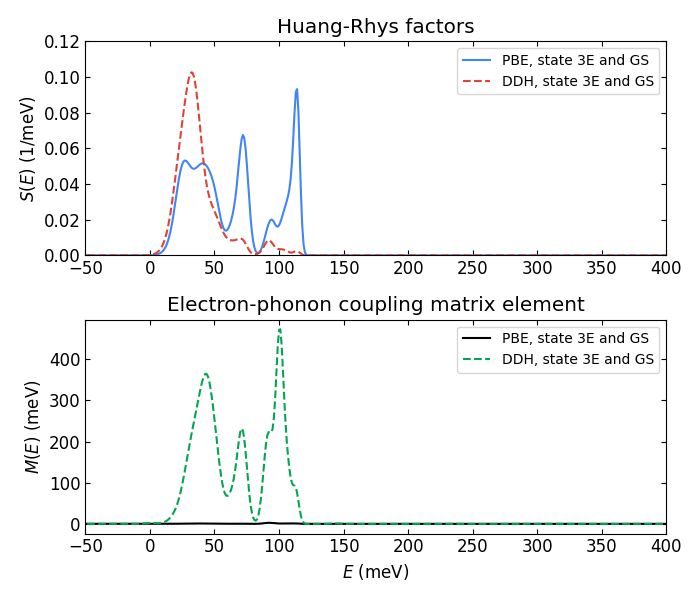

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [blue, red, goldenrod_yellow, emerald_green]

ax[0].plot(spectral_density_hrf_3E_state1_3A2_pbe[0], 
           spectral_density_hrf_3E_state1_3A2_pbe[1],
           color=colors[0],
           linestyle='-',
           label=r'PBE, state 3E and GS')

ax[0].plot(spectral_density_hrf_3E_state1_3A2_ddh[0], 
           spectral_density_hrf_3E_state1_3A2_ddh[1],
           color=colors[1],
           linestyle='--',
           label=r'DDH, state 3E and GS')

ax[1].plot(
    spectral_density_dH_dq_3E_state1_3A2_pbe[0],
    # spectral_density_dH_dq_3E_state1_3A2_pbe[1]*100,
    spectral_density_dH_dq_3E_state1_3A2_pbe[1],
    color='k',
    linestyle='-',
    # label=r'PBE, state 3E and GS ($\times$ 100)'
    label=r'PBE, state 3E and GS'
)

ax[1].plot(
    spectral_density_dH_dq_3E_state1_3A2_ddh[0],
    spectral_density_dH_dq_3E_state1_3A2_ddh[1],
    color=colors[3],
    linestyle='--',
    label=r'DDH, state 3E and GS'
)

ax[0].set_title('Huang-Rhys factors')
ax[1].set_title('Electron-phonon coupling matrix element')

for i in range(2):
    ax[i].legend(loc='upper right', fontsize=10)
    ax[1].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$S(E)$ (1/meV)')
    ax[1].set_ylabel('$M(E)$ (meV)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 0.12])
    # ax[1].set_ylim([0, 450])
    ax[i].set_xlim([-50, 400])

fig.tight_layout()
plt.show()

In [16]:
print(sum(dict_nonrad_3E_state1_3A2_pbe['hr_factors']))
indices = np.argsort(dict_nonrad_3E_state1_3A2_pbe['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_3E_state1_3A2_pbe['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_3E_state1_3A2_pbe['hr_factors'][ind],
        1 - 2 * dict_nonrad_3E_state1_3A2_pbe['hr_factors'][ind]
        ))


3.63528466930262
index     freq (meV)      hr_factor     1-2hr_factor
  35       24.806994      0.227663      0.544673
1189      114.281034      0.227549      0.544902
 599       73.614078      0.220089      0.559823
  41       26.025766      0.134741      0.730518
1174      111.973080      0.106315      0.787369
 598       72.932583      0.103066      0.793868
  44       26.222373      0.071076      0.857849
 590       71.105081      0.061110      0.877781
1193      115.272731      0.059275      0.881450
  92       33.069298      0.055073      0.889855


In [17]:
print(sum(dict_nonrad_3E_state1_3A2_ddh['hr_factors']))
indices = np.argsort(dict_nonrad_3E_state1_3A2_ddh['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_3E_state1_3A2_ddh['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_3E_state1_3A2_ddh['hr_factors'][ind],
        1 - 2 * dict_nonrad_3E_state1_3A2_ddh['hr_factors'][ind]
        ))


2.7104797693197105
index     freq (meV)      hr_factor     1-2hr_factor
  65       30.880647      0.385216      0.229569
  35       24.806994      0.289205      0.421591
   7       18.688819      0.128194      0.743612
 108       34.018233      0.118219      0.763562
  80       32.111217      0.115298      0.769405
 112       34.723223      0.084991      0.830017
 149       37.165585      0.083799      0.832402
  19       21.846450      0.079958      0.840083
 119       35.299982      0.075426      0.849148
  41       26.025766      0.047250      0.905500


In [18]:
# check normalization
print(np.sum(spectral_density_dH_dq_3E_state1_3A2_pbe[1] * (spectral_density_dH_dq_3E_state1_3A2_pbe[0][1] - spectral_density_dH_dq_3E_state1_3A2_pbe[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_3E_state1_3A2_pbe['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_3E_state1_3A2_pbe['freqs'])))

1.820502350821853e-42
1.820502350821853e-42


In [19]:
# check normalization
print(np.sum(spectral_density_dH_dq_3E_state1_3A2_ddh[1] * (spectral_density_dH_dq_3E_state1_3A2_ddh[0][1] - spectral_density_dH_dq_3E_state1_3A2_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_3E_state1_3A2_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_3E_state1_3A2_ddh['freqs'])))

4.5824760811136945e-40
4.5824760811136945e-40


## 2. Compute nonradiative rate

We can compute the lineshape function for both the radiative and non-radiative transitions at different temperatures, with a broadening parameter provided for each temperature.

In [20]:
temperatures = np.arange(0,450,50)
zpl_broadenings = np.ones_like(temperatures)*(8.26*1E-4 * 0.5) # meV (~200 MHz)

rad_lineshapes_pbe = []
nonrad_lineshapes_pbe = []
rad_lineshapes_ddh = []
nonrad_lineshapes_ddh = []

for temp, zpl_broadening in zip(temperatures, zpl_broadenings):
    tmp = nonrad_3E_state1_3A2_pbe.compute_lineshape_fft(
        dict_nonrad_3E_state1_3A2_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_pbe.append(tmp)
    print()
    
    tmp = nonrad_3E_state1_3A2_ddh.compute_lineshape_fft(
        dict_nonrad_3E_state1_3A2_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_ddh.append(tmp)
    print()
    
    tmp = nonrad_3E_state1_3A2_pbe.compute_nonrad_lineshape_fft(
        dict_nonrad_3E_state1_3A2_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_pbe.append(tmp)
    print()
    
    tmp = nonrad_3E_state1_3A2_ddh.compute_nonrad_lineshape_fft(
        dict_nonrad_3E_state1_3A2_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_ddh.append(tmp)
    print()

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:193: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981474

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981525

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:328: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 1.13626819427107e-20

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 2.8601566043717694e-18

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981471

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981522

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.099999999

<>:51: SyntaxWarning: invalid escape sequence '\G'
<>:51: SyntaxWarning: invalid escape sequence '\G'
/tmp/ipykernel_1009388/2968505899.py:51: SyntaxWarning: invalid escape sequence '\G'
  ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')


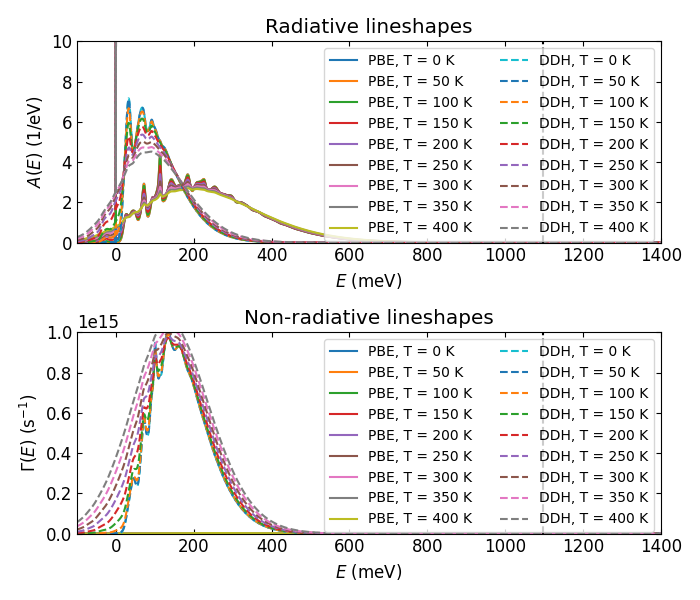

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [deep_violet, soft_coral, emerald_green, 'k', 'b', 'r']

for i, temp in enumerate(temperatures):
    ax[0].plot(
        rad_lineshapes_pbe[i][0],
        rad_lineshapes_pbe[i][1],
        # color=colors[i],
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )
    
for i, temp in enumerate(temperatures):
    ax[0].plot(
        rad_lineshapes_ddh[i][0],
        rad_lineshapes_ddh[i][1],
        # color=colors[i],
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )
    
for i, temp in enumerate(temperatures):
    ax[1].plot(
        nonrad_lineshapes_pbe[i][0],
        nonrad_lineshapes_pbe[i][1] * 2 * np.pi / hbar,
        # color=colors[i],
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )

for i, temp in enumerate(temperatures):
    ax[1].plot(
        nonrad_lineshapes_ddh[i][0],
        nonrad_lineshapes_ddh[i][1] * 2 * np.pi / hbar,
        # color=colors[i],
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )

ax[0].axvline(x=adiabatic_energy_3E_3A2, color='black', linestyle='--')
ax[1].axvline(x=adiabatic_energy_3E_3A2, color='black', linestyle='--')

ax[0].set_title('Radiative lineshapes')
ax[1].set_title('Non-radiative lineshapes')

for i in range(2):
    ax[i].legend(loc='upper right', ncols=2, fontsize=10)
    ax[i].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$A(E)$ (1/eV)')
    ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 10])
    ax[1].set_ylim([0, 1e15])
    ax[i].set_xlim([-100, 1400])

fig.tight_layout()
plt.show()

We can compute the nonradiative rate at the corresponding nonadiabatic transition energy.

In [22]:
print('Nonradiative, all modes, PBE, triplets')
non_rad_rates_pbe = []
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_pbe[i]):
        if abs(energy - adiabatic_energy_3E_3A2_pbe) < 0.01:
            rate = lineshape * 2 * np.pi / hbar
            non_rad_rates_pbe.append(rate)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp, energy, rate)
            )

print('Nonradiative, all modes, DDH, triplets')
non_rad_rates_ddh = []
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_ddh[i]):
        if abs(energy - adiabatic_energy_3E_3A2_ddh) < 0.01:
            rate = lineshape * 2 * np.pi / hbar
            non_rad_rates_ddh.append(rate)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp, energy, rate)
            )

Nonradiative, all modes, PBE, triplets
T =   0 K, Energy = 9.709999999987e+02 meV, rate = 1.806029114220e+09 1/s
T =  50 K, Energy = 9.709999999987e+02 meV, rate = 1.811413515663e+09 1/s
T = 100 K, Energy = 9.709999999987e+02 meV, rate = 1.840304985927e+09 1/s
T = 150 K, Energy = 9.709999999987e+02 meV, rate = 1.927138673753e+09 1/s
T = 200 K, Energy = 9.709999999987e+02 meV, rate = 2.088748053274e+09 1/s
T = 250 K, Energy = 9.709999999987e+02 meV, rate = 2.342729868655e+09 1/s
T = 300 K, Energy = 9.709999999987e+02 meV, rate = 2.707429703876e+09 1/s
T = 350 K, Energy = 9.709999999987e+02 meV, rate = 3.202548712998e+09 1/s
T = 400 K, Energy = 9.709999999987e+02 meV, rate = 3.850439706883e+09 1/s
Nonradiative, all modes, DDH, triplets
T =   0 K, Energy = 1.350999999998e+03 meV, rate = 2.178232983615e+07 1/s
T =  50 K, Energy = 1.350999999998e+03 meV, rate = 2.179423113907e+07 1/s
T = 100 K, Energy = 1.350999999998e+03 meV, rate = 2.208411927473e+07 1/s
T = 150 K, Energy = 1.350999999998

## Comparison between DDH and PBE NACs

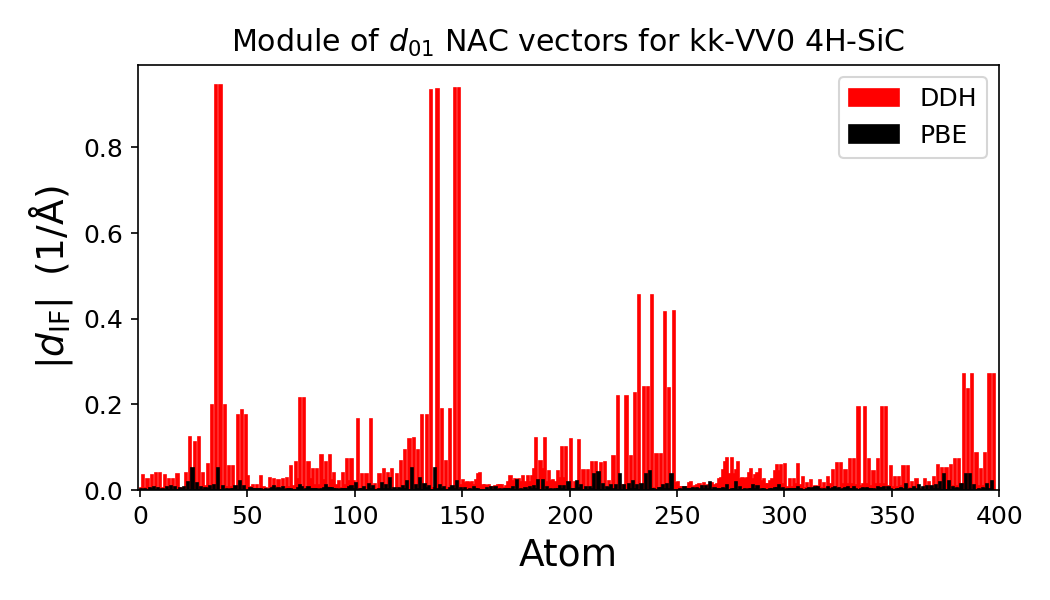

In [23]:
y1 = np.linalg.norm(nac_vec_3E_state1_3A2_ddh, axis=1)
y2 = np.linalg.norm(nac_vec_3E_state1_3A2_pbe, axis=1)
x = np.arange(len(y1))

fig, ax = plt.subplots(1, 1, figsize=(7, 4), dpi=150)

w = 1  # bar width

ax.bar(x + w/2, y1, width=w, edgecolor='r', facecolor='r',
       linewidth=0.8, label=r'DDH')
ax.bar(x - w/2, y2, width=w, edgecolor='k', facecolor='k',
       linewidth=0.8, label=r'PBE')

ax.set_xlabel(r'Atom', fontsize=18)
ax.set_ylabel(r'$|d_\mathrm{IF}|\;\;(1/\mathrm{\AA})$', fontsize=18)
ax.legend()
ax.set_title(r"Module of $d_{01}$ NAC vectors for kk-VV0 4H-SiC")
ax.set_xlim(xmin=-1,xmax=400)
fig.tight_layout()
plt.show()

<>:65: SyntaxWarning: invalid escape sequence '\m'
<>:65: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1009388/3232652185.py:65: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')


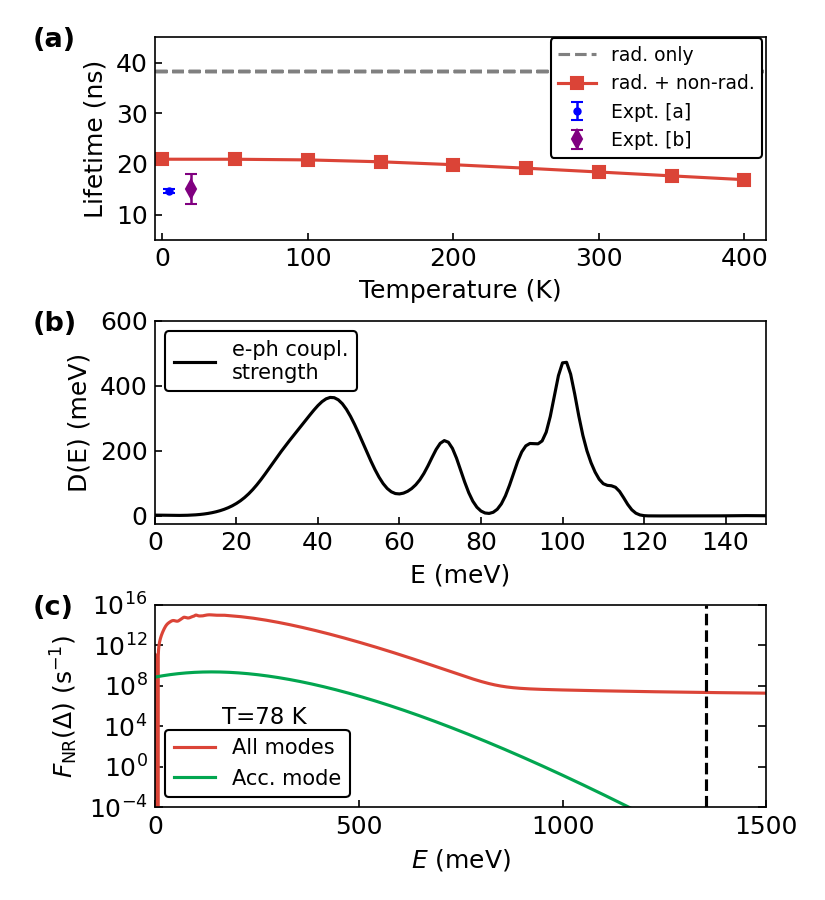

In [24]:
# import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# -----------------------------
rate_non_rad_pbe = np.array(non_rad_rates_pbe)
rate_non_rad_ddh = np.array(non_rad_rates_ddh)

data = np.load("SiC_triplets_effmode_T78K.npz")
E_eff  = data["x"]
LS_eff = data["y"]
# -----------------------------
fig, ax = plt.subplots(3, 1, figsize=(5.5, 6), dpi=150)
ax=ax.ravel()
#
rad_rate = 38.42
rad_rate = np.ones(len(non_rad_rates_ddh))*(1/rad_rate)*1e+9
lifetimes_pbe = 1/( rad_rate + non_rad_rates_pbe) * 1e+9
lifetimes_ddh = 1/( rad_rate + non_rad_rates_ddh) * 1e+9
#
ax[0].hlines(y=1/rad_rate*1e+9, xmin=-50, xmax=450, ls='--', color='gray', label=r'rad. only')
ax[0].plot(temperatures,lifetimes_ddh,c=red,marker='s',label=r'rad. + non-rad.')
ax[0].errorbar(
    x=[5], y=[14.7], yerr=[0.4],
    fmt='.', color='b', ecolor='b', elinewidth=1.2, capsize=3,
    label=r'Expt. [a]'
)
ax[0].errorbar(
    x=[20], y=[15.0], yerr=[3.0],
    fmt='d', color='purple', ecolor='purple', elinewidth=1.2, capsize=3,
    label=r'Expt. [b]'
)
ax[0].set_xlabel('Temperature (K)')
ax[0].set_ylabel('Lifetime (ns)')
ax[0].set_xlim(xmin=-5, xmax=415)
ax[0].set_ylim(ymin=5, ymax=45)
ax[0].legend(fontsize=9,edgecolor='k',framealpha=1.0, bbox_to_anchor=(0.82,0.7), loc='center')
ax[0].tick_params(direction='in', which='both')
# 
ax[1].plot(spectral_density_dH_dq_3E_state1_3A2_ddh[0],spectral_density_dH_dq_3E_state1_3A2_ddh[1],
        color='k',ls='-',label='e-ph coupl.\nstrength')
ax[1].set_xlabel('E (meV)')
ax[1].set_ylabel('D(E) (meV)')
ax[1].tick_params(direction='in', which='both')
ax[1].set_yticks([0,200,400,600])
ax[1].set_xlim([0, 150])
ax[1].set_ylim(ymax=600)
ax[1].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper left')
# 
ax[2].plot(nonrad_lineshapes_ddh[0][0], nonrad_lineshapes_ddh[0][1]*2*np.pi/hbar, color=red,linestyle='-',label='All modes')
ax[2].plot(E_eff, LS_eff, color=emerald_green, linestyle='-', label='Acc. mode')
ax[2].set_yscale('log')
ax[2].set_ylim(bottom=1e-4, top=1e16)
ax[2].yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
ax[2].yaxis.set_minor_locator(
    LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)
)
ax[2].yaxis.set_minor_formatter(NullFormatter())
ax[2].tick_params(axis='y', which='major', direction='in', length=4, right=True)
ax[2].tick_params(axis='y', which='minor', direction='in', length=2, right=True)
ax[2].tick_params(axis='x', which='major', direction='in', top=False)
ax[2].yaxis.set_ticks_position('both')
ax[2].set_yticks([1e-4, 1e0, 1e4, 1e8, 1e12, 1e16])
ax[2].set_xlabel('$E$ (meV)')
ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
ax[2].tick_params(axis='x', which='both', direction='in')
ax[2].text(0.11, 0.5, 'T=78 K', transform=ax[2].transAxes, ha='left', va='top', fontsize=11)
ax[2].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='lower left')
ax[2].set_xlim([-0, 1500])
ax[2].set_xticks([0, 500, 1000, 1500])
ax[2].axvline(x=adiabatic_energy_3E_3A2_ddh, color='black', linestyle='--')
#
labels = ['(a)', '(b)', '(c)']
for i, label in enumerate(labels):
    ax[i].text(
        -0.2, 1.05, label,
        transform=ax[i].transAxes,
        ha='left', va='top',
        fontsize=13, fontweight='bold'
    )

fig.tight_layout()
fig.subplots_adjust(hspace=0.4)
plt.show()

### Comparison PBE vs DDH

<>:16: SyntaxWarning: invalid escape sequence '\G'
<>:49: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\G'
<>:49: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1009388/630804134.py:16: SyntaxWarning: invalid escape sequence '\G'
  ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
/tmp/ipykernel_1009388/630804134.py:49: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')


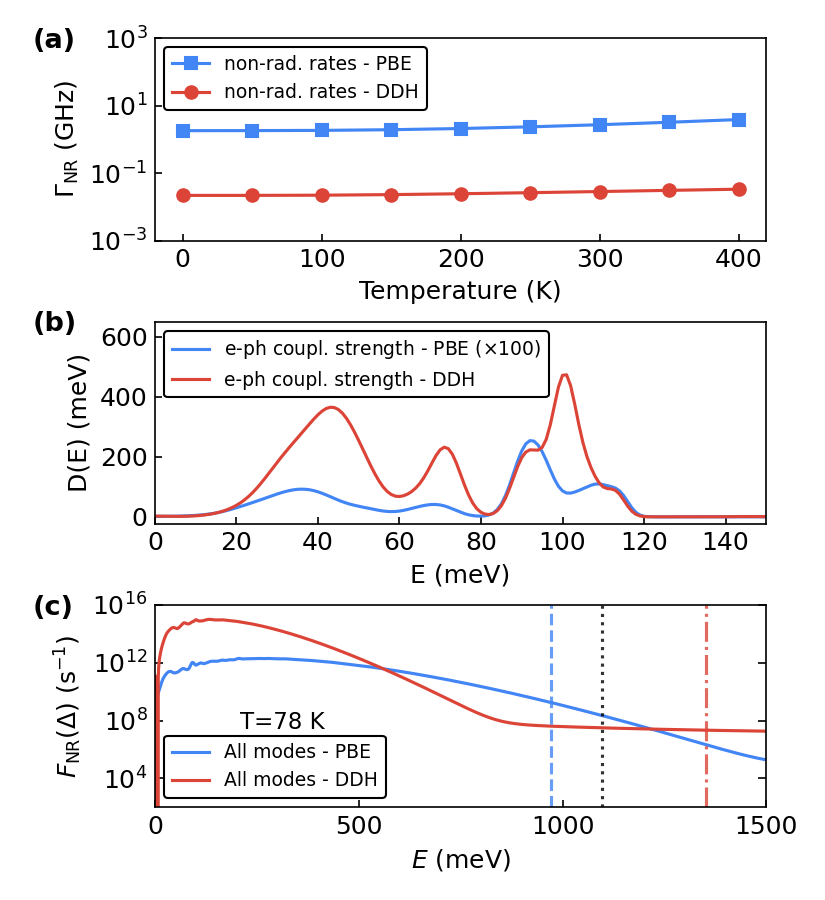

In [25]:
# import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# -----------------------------
rate_non_rad_pbe = np.array(non_rad_rates_pbe)
rate_non_rad_ddh = np.array(non_rad_rates_ddh)

# -----------------------------
fig, ax = plt.subplots(3, 1, figsize=(5.5, 6), dpi=150)
ax=ax.ravel()
#
ax[0].plot(temperatures, rate_non_rad_pbe*1e-9, c=blue, marker='s', label='non-rad. rates - PBE')
ax[0].plot(temperatures, rate_non_rad_ddh*1e-9, c=red, marker='o', label='non-rad. rates - DDH')
ax[0].set_xlabel('Temperature (K)')
ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
ax[0].set_yscale('log')
ax[0].set_ylim(bottom=1e-3,top=1e3)
ax[0].legend(fontsize=9,edgecolor='k',framealpha=1.0,loc='upper left')
ax[0].tick_params(direction='in', which='both')
# 
ax[1].plot(spectral_density_dH_dq_3E_state1_3A2_pbe[0],spectral_density_dH_dq_3E_state1_3A2_pbe[1]*100,
        color=blue,ls='-',label=r'e-ph coupl. strength - PBE ($\times 100$)')
ax[1].plot(spectral_density_dH_dq_3E_state1_3A2_ddh[0],spectral_density_dH_dq_3E_state1_3A2_ddh[1],
        color=red,ls='-',label='e-ph coupl. strength - DDH')
ax[1].set_xlabel('E (meV)')
ax[1].set_ylabel('D(E) (meV)')
ax[1].tick_params(direction='in', which='both')
ax[1].set_yticks([0,200,400,600])
ax[1].set_xlim([0, 150])
ax[1].set_ylim(ymax=650)
ax[1].legend(fontsize=9,edgecolor='k',framealpha=1.0, loc='upper left')
# 
ax[2].plot(nonrad_lineshapes_pbe[0][0], nonrad_lineshapes_pbe[0][1]*2*np.pi/hbar, color=blue, linestyle='-',label='All modes - PBE')
ax[2].plot(nonrad_lineshapes_ddh[0][0], nonrad_lineshapes_ddh[0][1]*2*np.pi/hbar, color=red, linestyle='-',label='All modes - DDH')
ax[2].set_yscale('log')
ax[2].set_ylim(bottom=1e2, top=1e16)
ax[2].yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
ax[2].yaxis.set_minor_locator(
    LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)
)
ax[2].yaxis.set_minor_formatter(NullFormatter())
ax[2].tick_params(axis='y', which='major', direction='in', length=4, right=True)
ax[2].tick_params(axis='y', which='minor', direction='in', length=2, right=True)
ax[2].tick_params(axis='x', which='major', direction='in', top=False)
ax[2].yaxis.set_ticks_position('both')
ax[2].set_yticks([1e4, 1e8, 1e12, 1e16])
ax[2].set_xlabel('$E$ (meV)')
ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
ax[2].tick_params(axis='x', which='both', direction='in')
ax[2].text(0.14, 0.475, 'T=78 K', transform=ax[2].transAxes, ha='left', va='top', fontsize=11)
ax[2].legend(fontsize=9,edgecolor='k',framealpha=1.0, loc='lower left')
ax[2].set_xlim([-0, 1500])
ax[2].set_xticks([0, 500, 1000, 1500])
ax[2].axvline(x=adiabatic_energy_3E_3A2_pbe, color=blue, alpha=0.8, linestyle='--')
ax[2].axvline(x=adiabatic_energy_3E_3A2_ddh, color=red, alpha=0.8, linestyle='-.')
ax[2].axvline(x=adiabatic_energy_3E_3A2, color='k', alpha=0.8, linestyle='dotted')
#
labels = ['(a)', '(b)', '(c)'] 
for i, label in enumerate(labels):
    ax[i].text(
        -0.2, 1.05, label,
        transform=ax[i].transAxes,
        ha='left', va='top',
        fontsize=13, fontweight='bold'
    )

fig.tight_layout()
fig.subplots_adjust(hspace=0.4)
plt.show()